# Interpretabilidad: valores de Shapley (SHAP) y LIME

El valor de Shapley de la variable $j$ para la fila $\mathbf x$ es su contribución marginal promedio sobre todos los subconjuntos $S$ de las demás variables:

$$\phi_j(\mathbf x) = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,(|F| - |S| - 1)!}{|F|!}\Big[f_{S \cup \{j\}}(\mathbf x) - f_S(\mathbf x)\Big].$$

Es la única atribución que cumple **eficiencia** ($\sum_j \phi_j = f(\mathbf x) - E[f]$), **simetría** (variables con igual aporte reciben igual valor), **nulidad** y **aditividad** (en un ensamble, los valores son la suma de los de sus árboles). Para modelos de árboles, TreeSHAP los calcula **exactamente** en tiempo polinomial. En clasificación se expresan en log-odds.

In [1]:
import os  # Rutas
import sys  # Configuración del intérprete
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # Evita un aviso de joblib en Windows
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../.."), os.path.abspath("../../entregable1")]  # e3, src y e1
import warnings  # Control de avisos
warnings.filterwarnings("ignore")  # Oculta avisos de versiones
import contextlib, io  # Silenciar un diagnóstico de joblib en Windows
from joblib.externals.loky import cpu_count  # Conteo de núcleos
with contextlib.redirect_stderr(io.StringIO()):  # joblib imprime un diagnóstico al no encontrar «wmic»
    cpu_count(only_physical_cores=True)  # Se calcula una vez (queda en caché)
import pickle  # Lectura de resultados
import numpy as np  # Cálculo numérico
import pandas as pd  # Tablas
import plotly.express as px  # Figuras rápidas
import plotly.graph_objects as go  # Figuras detalladas
from plotly.subplots import make_subplots  # Paneles
from IPython.display import Markdown, display  # Texto enriquecido
from e1.figuras import mostrar, AZUL, ROJO, VERDE, AMBAR, GRIS, MORADO  # Estilo de figuras (tema claro del informe)
from e3 import config as c3, datos as dd, modelos as mo, optimizadores as op, experimento as ex  # Código del entregable
c3.fijar_semilla()  # Semilla global (42)
pd.set_option("display.width", 170)  # Ancho de las tablas
pd.set_option("display.max_columns", 30)  # Columnas visibles
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # Cuatro decimales
COLORES = {"Grid Search": GRIS, "Random Search": AMBAR, "Bayesiana (Optuna TPE)": AZUL, "Genética (DEAP)": VERDE, "Successive Halving": MORADO}  # Color por optimizador
import shap  # Valores de Shapley
import matplotlib.pyplot as plt  # Gráficos de SHAP
from e3 import interpretabilidad as it, evaluacion as ev  # Interpretabilidad
tabla = pd.read_csv(c3.RESULTADOS / "tabla_maestra.csv")  # Tabla maestra
ext = tabla.groupby(["tarea", "modelo", "balanceo", "optimizador"])[["AUC-PR", "RMSE"]].mean().reset_index()  # Bucle externo
mejor_clf = ext[ext["tarea"] == "clf"].sort_values("AUC-PR", ascending=False).iloc[0]  # Mejor clasificador
mejor_xgb = ext[(ext["tarea"] == "clf") & (ext["modelo"] == "XGBoost")].sort_values("AUC-PR", ascending=False).iloc[0]  # Mejor XGBoost (para LIME)
mejor_reg = ext[(ext["tarea"] == "reg") & ext["modelo"].isin(["Random Forest", "XGBoost", "Árbol de decisión"])].sort_values("RMSE").iloc[0]  # Mejor regresor de árboles
pd.DataFrame([mejor_clf, mejor_xgb, mejor_reg], index=["mejor clasificador", "mejor XGBoost (clasificación)", "mejor regresor de árboles"])

,tarea,modelo,balanceo,optimizador,AUC-PR,RMSE
mejor clasificador,clf,XGBoost,Sin balanceo,Genética (DEAP),0.6792,NaN
mejor XGBoost (clasificación),clf,XGBoost,Sin balanceo,Genética (DEAP),0.6792,NaN
mejor regresor de árboles,reg,XGBoost,—,Genética (DEAP),NaN,0.4808


## Clasificación: interpretabilidad global

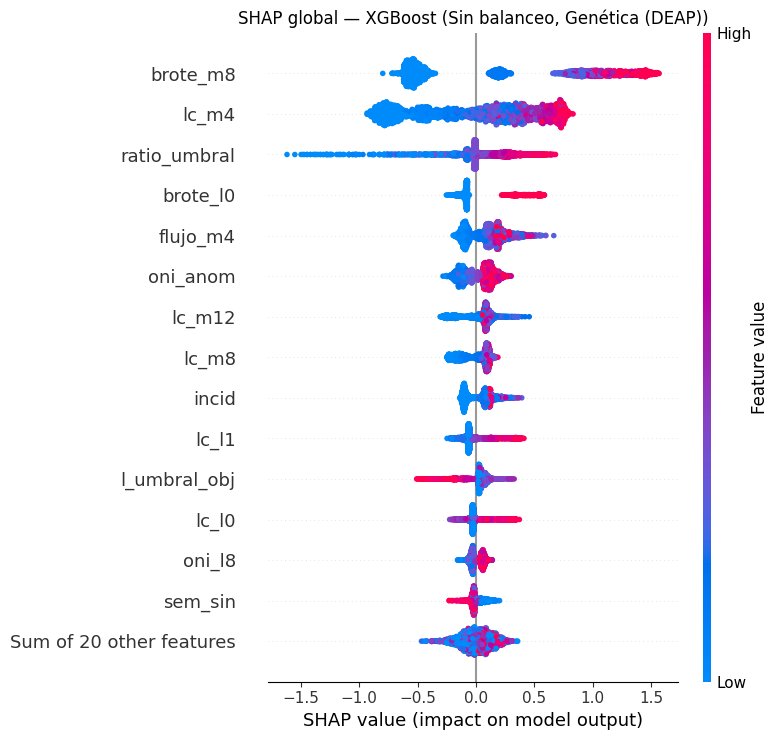

,media |SHAP| (log-odds)
brote_m8,0.7391
lc_m4,0.4600
ratio_umbral,0.2001
brote_l0,0.1962
flujo_m4,0.1532
oni_anom,0.1152
lc_m12,0.1129
lc_m8,0.1099
incid,0.1049
lc_l1,0.1048


In [2]:
tr, va, te = dd.cargar()  # Periodos
pipe, est, prep = it.reajustar("clf", mejor_clf["modelo"], mejor_clf["balanceo"], mejor_clf["optimizador"])  # Mejor clasificador
muestra = te.sample(3000, random_state=c3.SEMILLA)  # Filas de la prueba a explicar
Xp = prep(muestra[dd.X_COLS].to_numpy())  # Espacio en que trabaja el modelo (estandarizado)
sv = it.shap_arbol(est, Xp)  # Valores SHAP exactos
sv.data = muestra[dd.X_COLS].to_numpy()  # Se muestran los valores originales (no estandarizados) en el eje de color
plt.figure()  # Figura nueva
shap.plots.beeswarm(sv, max_display=15, show=False)  # Gráfico resumen
plt.title(f"SHAP global — {mejor_clf['modelo']} ({mejor_clf['balanceo']}, {mejor_clf['optimizador']})")  # Título
plt.tight_layout()  # Ajuste
plt.show()  # Muestra
imp = pd.Series(np.abs(sv.values).mean(axis=0), index=dd.X_COLS).sort_values(ascending=False)  # Importancia media |SHAP|
imp.head(10).to_frame("media |SHAP| (log-odds)")

**Interpretación.** El modelo se apoya sobre todo en la **historia reciente del brote**: la proporción de semanas en brote en las últimas 8 (`brote_m8`) es, de lejos, la variable con mayor impacto, seguida del log de casos de 4 semanas, los casos frente al umbral objetivo y el brote actual. Después aparecen el **flujo de personas** y **El Niño** (`oni_anom`). En el gráfico de enjambre, los valores altos (rojo) de estas variables empujan hacia el brote. Las variables climáticas locales tienen impactos pequeños, coherente con todo el EDA.

## Clasificación: interpretabilidad local

Dos filas de la prueba: un brote **bien anticipado** (verdadero positivo con probabilidad alta) y un brote **no anticipado** (falso negativo con probabilidad baja, el error más costoso).

Brote bien anticipado: Floridablanca (Santander), semana del 2023-09-11 · probabilidad 0.930 · casos en t: 54


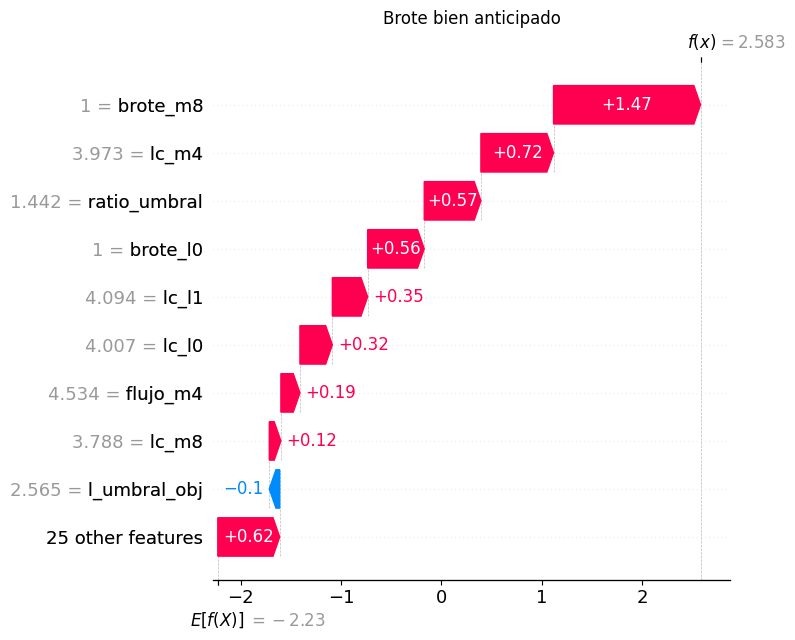

Brote no anticipado (falso negativo): Arenal (Bolívar), semana del 2023-02-20 · probabilidad 0.009 · casos en t: 0


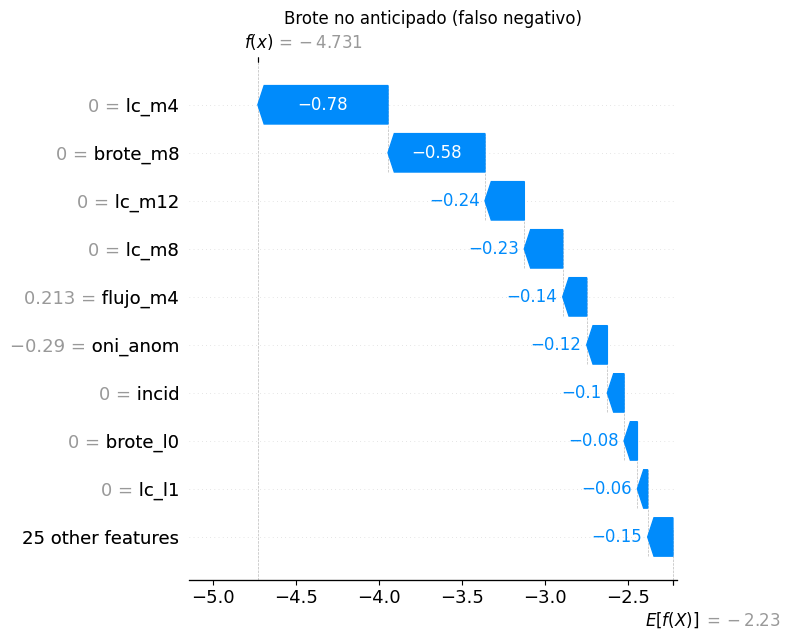

In [3]:
p = ev.metricas_clf  # (solo para recordar la función de métricas)
proba = pipe.predict_proba(muestra[dd.X_COLS].to_numpy())[:, 1]  # Probabilidades de la muestra
y_m = muestra["y"].to_numpy()  # Objetivo
i_bien = int(np.argmax(np.where(y_m == 1, proba, -1)))  # Brote con la probabilidad más alta
i_mal = int(np.argmin(np.where(y_m == 1, proba, 2)))  # Brote con la probabilidad más baja
for i, titulo in [(i_bien, "Brote bien anticipado"), (i_mal, "Brote no anticipado (falso negativo)")]:  # Dos casos
    fila = muestra.iloc[i]  # Fila
    print(f"{titulo}: {fila['municipio']} ({fila['departamento']}), semana del {fila['week_start'].date()} · probabilidad {proba[i]:.3f} · casos en t: {int(fila['casos_totales'])}")
    plt.figure()  # Figura
    shap.plots.waterfall(sv[i], max_display=10, show=False)  # Cascada
    plt.title(titulo)  # Título
    plt.tight_layout()  # Ajuste
    plt.show()  # Muestra

**Interpretación.** En el **brote bien anticipado** (Floridablanca, septiembre de 2023, probabilidad 0,93) casi todas las variables de historia empujan hacia el brote: el municipio ya venía con semanas en brote y casos sobre su umbral. En el **brote no anticipado** (Arenal, febrero de 2023, probabilidad 0,009) el municipio tenía **0 casos** en la semana de la predicción y ninguna semana reciente en brote: todas las variables de historia empujan hacia «no brote». Es un brote que aparece sin señal previa en el propio municipio; solo información externa (vecinos en brote, movilidad) podría anticiparlo, lo que vuelve a apuntar a las variables de vecindad.

## XGBoost: SHAP frente a LIME

LIME perturba la fila, pondera las perturbaciones por cercanía y ajusta una **regresión lineal local**; sus pesos dependen de la discretización, del tamaño del vecindario y de la muestra aleatoria. SHAP reparte la predicción con una regla axiomática (eficiencia, simetría, aditividad) y, para árboles, es exacto.

In [4]:
pipe_x, est_x, prep_x = it.reajustar("clf", "XGBoost", mejor_xgb["balanceo"], mejor_xgb["optimizador"])  # Mejor XGBoost
Xp_x = prep_x(muestra[dd.X_COLS].to_numpy())  # Muestra transformada
sv_x = it.shap_arbol(est_x, Xp_x)  # SHAP
ent_x = prep_x(dd.submuestra(tr, 5000)[dd.X_COLS].to_numpy())  # Datos de referencia para LIME
comparacion = []  # SHAP frente a LIME
for i, nombre in [(i_bien, "brote bien anticipado"), (i_mal, "brote no anticipado")]:  # Mismas dos filas
    pesos, r2 = it.lime_local(est_x, ent_x, Xp_x[i])  # LIME
    pesos["variable"] = pesos["condición"].str.extract(r"([a-z][a-z_0-9]*)")[0]  # Variable de cada condición
    top_shap = pd.Series(sv_x.values[i], index=dd.X_COLS).abs().sort_values(ascending=False).head(10)  # 10 variables con mayor |SHAP|
    comun = len(set(top_shap.index) & set(pesos["variable"]))  # Coincidencias
    display(Markdown(f"**{nombre}** · R² del modelo lineal local de LIME: {r2:.2f} · variables en común entre los 10 principales: {comun} de 10"))
    display(pesos.assign(**{"SHAP de la variable": pesos["variable"].map(pd.Series(sv_x.values[i], index=dd.X_COLS))}).round(3))  # Tabla
    comparacion.append({"fila": nombre, "R² LIME": r2, "coincidencias top 10": comun})
pd.DataFrame(comparacion)

**brote bien anticipado** · R² del modelo lineal local de LIME: 0.50 · variables en común entre los 10 principales: 8 de 10

,condición,peso LIME,variable,SHAP de la variable
0,brote_m8 > -0.43,0.0690,brote_m8,1.4660
1,lc_m4 > 0.21,0.0510,lc_m4,0.7240
2,ratio_umbral > 0.35,0.0450,ratio_umbral,0.5650
3,flujo_m4 > 0.22,0.0340,flujo_m4,0.1900
4,brote_l0 > -0.34,0.0290,brote_l0,0.5640
5,l_umbral_obj > 0.54,-0.0250,l_umbral_obj,-0.1040
6,oni_anom > 0.58,0.0250,oni_anom,0.0700
7,lc_m8 > 0.19,0.0210,lc_m8,0.1160
8,lc_l1 > 0.14,0.0180,lc_l1,0.3520
9,oni_l8 > 0.55,0.0130,oni_l8,0.0610


**brote no anticipado** · R² del modelo lineal local de LIME: 0.29 · variables en común entre los 10 principales: 7 de 10

,condición,peso LIME,variable,SHAP de la variable
0,brote_m8 <= -0.43,-0.0680,brote_m8,-0.5840
1,-0.50 < ratio_umbral <= 0.35,0.0300,ratio_umbral,-0.0080
2,brote_l0 <= -0.34,-0.0260,brote_l0,-0.0800
3,-0.83 < oni_anom <= -0.05,-0.0160,oni_anom,-0.1240
4,lc_l1 <= -0.61,-0.0110,lc_l1,-0.0620
5,-0.64 < flujo_m4 <= -0.36,-0.0110,flujo_m4,-0.1450
6,lc_m12 <= -0.67,0.0090,lc_m12,-0.2370
7,l_umbral_obj <= -0.84,0.0070,l_umbral_obj,0.0220
8,lc_l2 <= -0.61,-0.0070,lc_l2,-0.0120
9,oni_l8 <= -0.83,-0.0070,oni_l8,-0.0330


,fila,R² LIME,coincidencias top 10
0,brote bien anticipado,0.5028,8
1,brote no anticipado,0.2882,7


In [5]:
import scipy.stats as ss  # Correlación de rangos
rho = []  # Estabilidad de LIME frente a SHAP en 20 filas
for i in range(20):  # Filas
    pesos, _ = it.lime_local(est_x, ent_x, Xp_x[i], num=34)  # Todas las variables
    pesos["variable"] = pesos["condición"].str.extract(r"([a-z][a-z_0-9]*)")[0]  # Variable
    l = pesos.groupby("variable")["peso LIME"].sum().reindex(dd.X_COLS).fillna(0)  # Peso por variable
    rho.append(ss.spearmanr(np.abs(l), np.abs(sv_x.values[i]))[0])  # Concordancia de importancias
print(f"Correlación de Spearman entre |LIME| y |SHAP| por fila (20 filas): mediana {np.median(rho):.2f}, rango {np.min(rho):.2f} a {np.max(rho):.2f}")

Correlación de Spearman entre |LIME| y |SHAP| por fila (20 filas): mediana 0.69, rango 0.42 a 0.82


**Interpretación.** LIME y SHAP coinciden mejor en el brote bien anticipado que en el falso negativo (las coincidencias y el R² del modelo lineal local de LIME están en las tablas), y la concordancia general entre las importancias es solo moderada (correlación de rangos por fila en el rango reportado arriba). Las diferencias metodológicas lo explican: LIME **discretiza** las variables en cuartiles y ajusta una regresión lineal a perturbaciones aleatorias, así que depende del tamaño del vecindario, de la semilla y de la discretización, y no garantiza que sus pesos sumen la predicción; SHAP (TreeSHAP) es **exacto** para árboles y cumple eficiencia, simetría y aditividad. Divergen más cuando el modelo es muy no lineal alrededor de la fila (como en el falso negativo, en una zona plana de probabilidad casi 0, donde el R² de LIME cae) o cuando hay variables colineales, entre las que LIME reparte el peso de forma inestable.

## Regresión: SHAP del mejor regresor de árboles

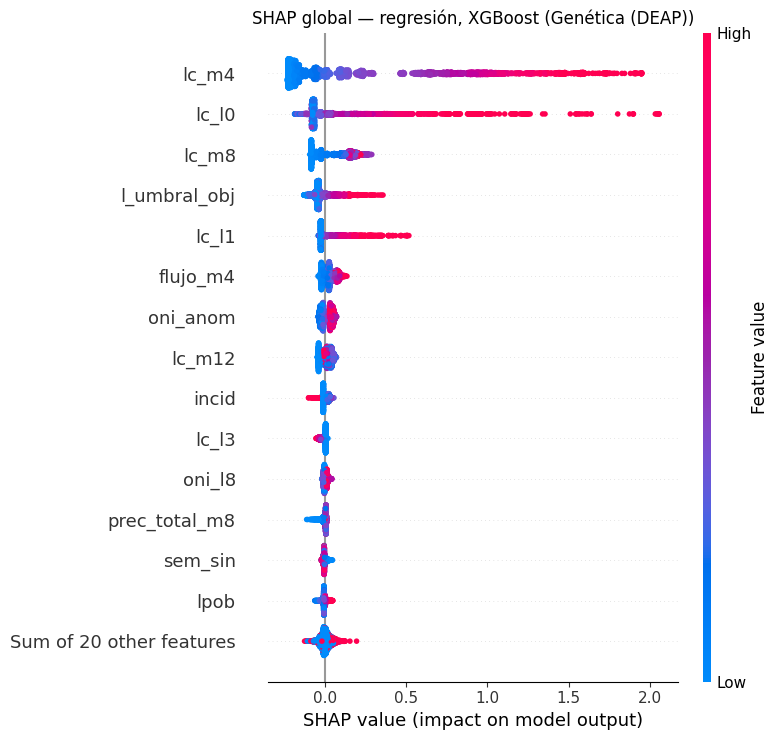

Semana epidémica bien predicha: Caloto, semana del 2024-03-18 · observado 2.89 · predicho 2.89


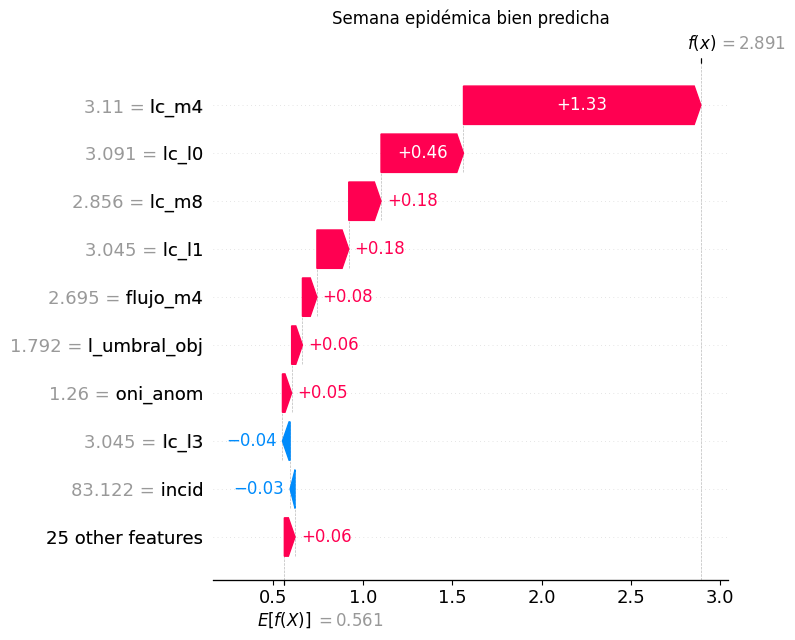

Mayor error de la muestra: Uribia, semana del 2024-10-14 · observado 2.94 · predicho 0.55


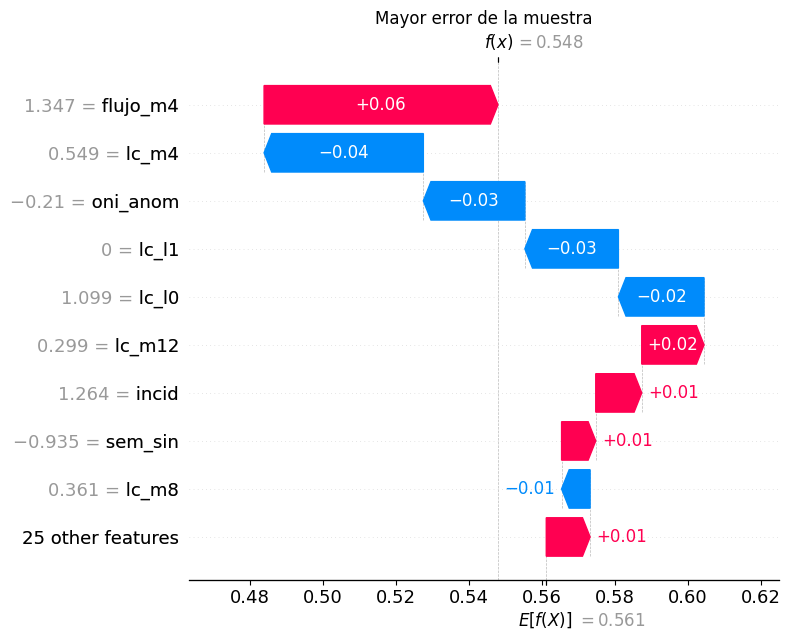

In [6]:
pipe_r, est_r, prep_r = it.reajustar("reg", mejor_reg["modelo"], "—", mejor_reg["optimizador"])  # Mejor regresor
Xp_r = prep_r(muestra[dd.X_COLS].to_numpy())  # Muestra transformada
sv_r = it.shap_arbol(est_r, Xp_r, tarea="reg")  # SHAP (en escala log(1 + casos))
sv_r.data = muestra[dd.X_COLS].to_numpy()  # Valores originales
plt.figure()  # Figura
shap.plots.beeswarm(sv_r, max_display=15, show=False)  # Resumen
plt.title(f"SHAP global — regresión, {mejor_reg['modelo']} ({mejor_reg['optimizador']})")  # Título
plt.tight_layout()  # Ajuste
plt.show()  # Muestra
pred_r = pipe_r.predict(muestra[dd.X_COLS].to_numpy())  # Predicciones
err = np.abs(muestra["y_reg"].to_numpy() - pred_r)  # Error absoluto
for i, titulo in [(int(np.argmin(err + (muestra["y_reg"].to_numpy() < 2) * 10)), "Semana epidémica bien predicha"), (int(np.argmax(err)), "Mayor error de la muestra")]:  # Dos casos
    fila = muestra.iloc[i]  # Fila
    print(f"{titulo}: {fila['municipio']}, semana del {fila['week_start'].date()} · observado {fila['y_reg']:.2f} · predicho {pred_r[i]:.2f}")
    plt.figure()  # Figura
    shap.plots.waterfall(sv_r[i], max_display=10, show=False)  # Cascada
    plt.title(titulo)  # Título
    plt.tight_layout()  # Ajuste
    plt.show()  # Muestra

**Interpretación.** En regresión el patrón es el mismo: las medias y rezagos del log de casos dominan, y El Niño y el flujo de personas vienen después. El error más grande de la muestra (Uribia, octubre de 2024) es otra vez un brote súbito: el modelo predice 0,55 (≈ 0,7 casos) y ocurren ≈ 18. La cascada muestra que las variables de historia, bajas en ese momento, arrastran la predicción hacia abajo.